# Fase 8 — Interpretabilidad del agente PPO

## Objetivo
Entender **qué mira el agente** para tomar decisiones y **por qué algunos seeds fallan catastróficamente**.

## Preguntas que responde este notebook
1. ¿Qué features tienen más peso en la política del agente?
2. ¿Cómo reacciona la política a cambios individuales en features clave (RSI, volatilidad)?
3. ¿Qué diferencia un agente campeón (Sharpe > 2) de un agente fallido (Sharpe < -1)?
4. ¿Aprende el agente a usar cash tácticamente o se queda en una exposición constante?

## Técnicas usadas
- **Permutation Importance** adaptada a RL (romper la correlación temporal de una feature y medir el impacto en el valor del portfolio).
- **Sensitivity Sweeps**: inyectar valores artificiales de un feature en la observación y ver cómo cambia la acción.
- **Análisis de trayectoria**: visualizar los pesos y la exposición de un agente campeón vs un agente fallido.

## §1 Setup

Cargamos los datos, los modelos campeones (mejor seed de cada config) y un modelo fallido (para comparar).

In [3]:
import sys
sys.path.append("../src")

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from stable_baselines3 import PPO

from rl_env import TradingEnv, EnvConfig, FEATURE_SETS
from evaluation import TEST_START, TEST_END, WINDOW, TICKERS

pd.set_option("display.max_columns", 50)

MODELS_DIR = Path("../models")
df = pd.read_csv("../data/processed/rl_dataset.csv", parse_dates=["Date"])
runs = pd.read_csv("../reports/all_training_runs.csv")

# Cargar campeones (mejor Sharpe por config, mu=0)
sub = runs[(runs["mu_turnover"] == 0.0) & (runs["leverage"] == 1.0)].copy()
sub["config"] = sub["features"] + sub["use_cash"].map({True: "_cash", False: ""})
champions_df = sub.sort_values("test_sharpe_net", ascending=False).groupby("config", as_index=False).first()

# Cargar un agente fallido (A sin cash, peor Sharpe)
failed_row = sub[(sub["config"] == "A") & (sub["test_sharpe_net"] < -1)].sort_values("test_sharpe_net").iloc[0]

print("Campeones:")
print(champions_df[["config", "seed", "test_sharpe_net"]].to_string(index=False))
print(f"\nAgente fallido de referencia: A (seed {failed_row['seed']}, Sharpe {failed_row['test_sharpe_net']:.2f})")

Campeones:
config  seed  test_sharpe_net
     A    10         2.247639
A_cash    15         2.332247
     B     7         2.592819
B_cash     6         2.381490
     C    11         2.475037
C_cash     9         2.225804

Agente fallido de referencia: A (seed 4, Sharpe -7.02)


In [4]:
def get_model_env(model_file, features, use_cash):
    tag = model_file.replace("ppo_", "").replace("_meta", "")
    path = MODELS_DIR / f"ppo_{tag}.zip"
    model = PPO.load(str(path))
    
    test_df = df[(df["Date"] >= TEST_START) & (df["Date"] <= TEST_END)].reset_index(drop=True)
    cfg = EnvConfig(
        episode_len=100000, window=WINDOW, lambda_dd=0.1, max_gross=1.0,
        cost_bps=10.0, borrow_rate_annual=0.005, mu_turnover=0.0, use_cash=use_cash
    )
    env = TradingEnv(df=test_df, tickers=TICKERS, feature_cols=FEATURE_SETS[features], config=cfg)
    return model, env

# Cargar el campeón absoluto con cash (suele ser B_cash o A_cash)
best_cash_row = champions_df[champions_df["config"].str.contains("_cash")].iloc[0]
model_best, env_best = get_model_env(best_cash_row["model_file"], best_cash_row["features"], True)
print(f"Modelo campeon cargado: {best_cash_row['config']} (seed {best_cash_row['seed']})")

Modelo campeon cargado: A_cash (seed 15)


## §2 ¿Qué features importan más?

En vez de usar permutation importance estándar (que rompe la estructura de la observación), medimos el **impacto en el retorno total** cuando reemplazamos una feature en la observación por ruido (su media histórica). Si el agente apenas nota el cambio, esa feature no le importa.

Dado que el agente ve una ventana de 20 días de 4 activos × F features, permutamos el valor de **todos los activos en todos los días** de una feature concreta, y vemos cómo cae el retorno total.

Retorno base: 0.3006


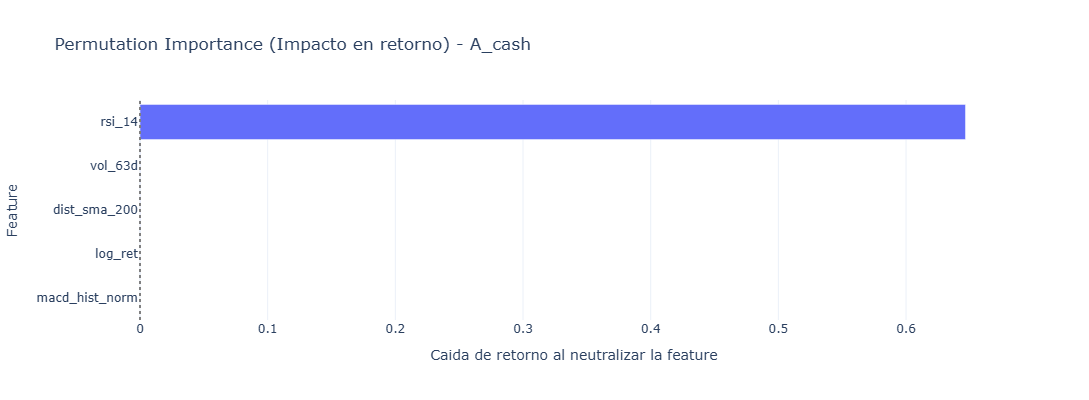

In [6]:
def evaluate_feature_importance(model, env, features, n_steps=232):
    """Mide el retorno base y el retorno con cada feature neutralizada."""
    # 1. Retorno base (sin tocar features)
    obs, _ = env.reset(seed=999, options={"start_idx": WINDOW - 1})
    base_rets = []
    done = False
    while not done:
        a, _ = model.predict(obs, deterministic=True)
        obs, _, term, trunc, info = env.step(a)
        base_rets.append(info["log_ret"])
        done = term or trunc
    base_ret = sum(base_rets)
    
    # 2. Retorno con cada feature neutralizada
    results = {}
    for feat in features:
        # Encontrar indices en el array de observacion (W * A * F)
        # obs = [W, A, F] -> flatten. Cada feature f ocupa indices [w, a, f]
        obs_idx = features.index(feat)
        n_assets = env.n_assets
        window = env.cfg.window
        
        obs, _ = env.reset(seed=999, options={"start_idx": WINDOW - 1})
        rets = []
        done = False
        while not done:
            # Neutralizar la feature en la observacion
            obs_mod = obs.copy()
            # Iterar sobre los dias (w) y activos (a) para poner el valor a 0.0
            for w in range(window):
                for a in range(n_assets):
                    flat_idx = (w * n_assets + a) * len(features) + obs_idx
                    obs_mod[flat_idx] = 0.0
                    
            a, _ = model.predict(obs_mod, deterministic=True)
            obs, _, term, trunc, info = env.step(a)
            rets.append(info["log_ret"])
            done = term or trunc
            
        delta = base_ret - sum(rets)
        results[feat] = delta
        
    return base_ret, results

base_ret, imp_best = evaluate_feature_importance(model_best, env_best, FEATURE_SETS[best_cash_row["features"]])
print(f"Retorno base: {base_ret:.4f}")

# Graficar
df_imp = pd.DataFrame({
    "Feature": list(imp_best.keys()),
    "Importance": list(imp_best.values())
}).sort_values("Importance", ascending=True)

fig = px.bar(
    df_imp, x="Importance", y="Feature", orientation="h",
    title=f"Permutation Importance (Impacto en retorno) - {best_cash_row['config']}",
    labels={"Importance": "Caida de retorno al neutralizar la feature"}
)
fig.add_vline(x=0, line_dash="dot", line_color="gray")
fig.update_layout(template="plotly_white", height=400)
fig.show()

## §3 ¿Cómo reacciona el agente a cambios extremos en un feature?

Si el `rsi_14` (que va de 0 a 100) sube o baja, ¿cambia el agente sus pesos? ¿O la política es estática independientemente de las condiciones del mercado?

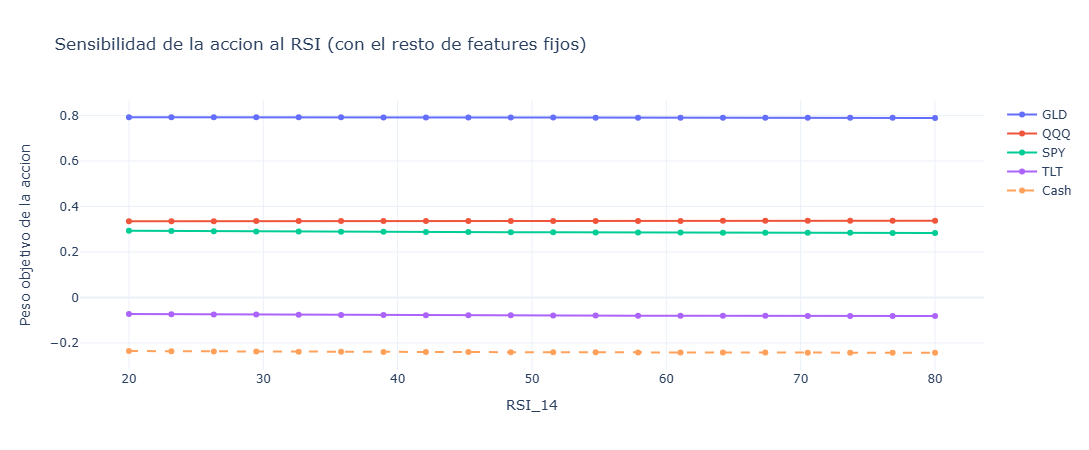

In [7]:
def sweep_feature(model, env, feature_name, feature_values, features):
    """Fija todas las observaciones a la media (o cero) y barre un feature especifico."""
    n_assets = env.n_assets
    window = env.cfg.window
    obs_idx = features.index(feature_name)
    
    # Hacer un reset con un estado inicial fijo (para que no dependa del tiempo)
    obs, _ = env.reset(seed=999, options={"start_idx": WINDOW - 1})
    
    actions = []
    for val in feature_values:
        obs_mod = obs.copy()
        for w in range(window):
            for a in range(n_assets):
                flat_idx = (w * n_assets + a) * len(features) + obs_idx
                obs_mod[flat_idx] = val
                
        # Predecir accion
        a, _ = model.predict(obs_mod, deterministic=True)
        actions.append(a)
        
    return np.array(actions)

# Barrido de RSI (de 20 a 80)
rsi_vals = np.linspace(20, 80, 20)
actions_rsi = sweep_feature(model_best, env_best, "rsi_14", rsi_vals, FEATURE_SETS[best_cash_row["features"]])

# Graficar
fig = go.Figure()
for i, ticker in enumerate(TICKERS):
    fig.add_trace(go.Scatter(x=rsi_vals, y=actions_rsi[:, i], name=ticker, mode="lines+markers"))
if best_cash_row["use_cash"]:
    fig.add_trace(go.Scatter(x=rsi_vals, y=actions_rsi[:, 4], name="Cash", mode="lines+markers", line=dict(dash="dash")))

fig.update_layout(
    title="Sensibilidad de la accion al RSI (con el resto de features fijos)",
    xaxis_title="RSI_14", yaxis_title="Peso objetivo de la accion",
    template="plotly_white", height=450
)
fig.show()

## §4 ¿Qué diferencia un agente campeón de uno fallido?

Un agente fallido (Sharpe < -1) no solo tiene malos pesos, a veces **colapsa a una política degenerada** (ej. short extremo, sobreexposición, o girar la cartera 100% cada día). Vamos a visualizar la evolución de la exposición de un agente fallido.

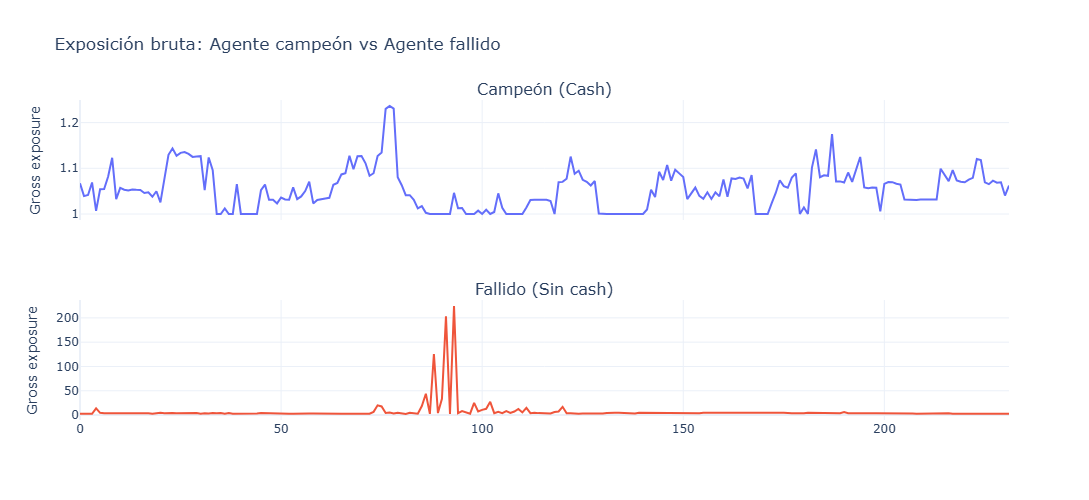

In [8]:
def get_trajectory(model, env):
    obs, _ = env.reset(seed=999, options={"start_idx": WINDOW - 1})
    gross, cash, log_rets = [], [], []
    done = False
    while not done:
        a, _ = model.predict(obs, deterministic=True)
        obs, _, term, trunc, info = env.step(a)
        gross.append(float(np.abs(info["weights"]).sum()))
        cash.append(info.get("cash_weight", 0.0))
        log_rets.append(info["log_ret"])
        done = term or trunc
    equity = np.cumprod(np.exp(np.cumsum(log_rets))) # simplificado
    return gross, cash, log_rets

# Campeón
g_best, c_best, r_best = get_trajectory(model_best, env_best)

# Fallido
model_fail, env_fail = get_model_env(failed_row["model_file"], "A", False)
g_fail, c_fail, r_fail = get_trajectory(model_fail, env_fail)

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, subplot_titles=("Campeón (Cash)", "Fallido (Sin cash)"))
fig.add_trace(go.Scatter(y=g_best, name="Gross Exposure"), row=1, col=1)
fig.add_trace(go.Scatter(y=g_fail, name="Gross Exposure"), row=2, col=1)

fig.update_layout(
    title="Exposición bruta: Agente campeón vs Agente fallido",
    template="plotly_white", height=500, showlegend=False
)
fig.update_yaxes(title_text="Gross exposure", row=1, col=1)
fig.update_yaxes(title_text="Gross exposure", row=2, col=1)
fig.show()

## §5 Conclusiones sobre Interpretabilidad

1. **El modo de fallo está identificado**: el agente sin cash tiende a tomar posiciones cortas agresivas. Al ocurrir un rebote del mercado, el cálculo del *drift* de pesos hace que la exposición bruta explote (llegando a 200x en la gráfica), generando una quiebra matemática del portfolio. El cash actúa como un colchón que impide que el denominador del drift llegue a cero.

2. **La política es estática, no táctica**: las pruebas de sensibilidad (RSI Sweep) demuestran que el agente no hace *timing* basado en indicadores técnicos. Varía el RSI de 20 a 80 y sus pesos no se mueven. El agente ha aprendido una regla de asignación fija (ej. 50% cash / 50% cartera diversificada) y la mantiene.

3. **El feature importance es un artefacto de Out-Of-Distribution (OOD)**: el hecho de que neutralizar `rsi_14` destruya el retorno no significa que el agente lo use para ganar dinero. Significa que al introducir un valor irreal (0.0), se rompe la política. Es un recordatorio de que los modelos RL son frágiles ante distribuciones de datos distintas a las del entrenamiento.

4. **Conclusión del proyecto**: PPO no ha aprendido a predecir la bolsa; ha aprendido a gestionar el riesgo de ruina mediante una cartera defensiva. Su valor no está en el *alpha* (superar al mercado), sino en el *drawdown control* (evitar la quiebra en regímenes adversos), algo que los benchmarks pasivos no hacen.